# Paper 3 — Phase 4: matched seed-42 continuation to 100,000 steps

**Purpose:** Test the training-budget hypothesis while preserving the original independent Phase 3 result. Continue the **β = 4 and β = 1, seed 42** models from their **real 30,000-step resumable checkpoints** to **50k, 75k and 100k updates**. At every milestone, archive **both `latest.pt` and `model.pt`**, regenerate Figure 7A/B from trained weights, and record quantitative diagnostics. Finally compare the four matched checkpoints.

**Source integrity:** This notebook does not modify the repository source, the Phase 3 Git commit, the original Drive checkpoints or any original Figure 7 artifacts. All Phase 4 training uses the existing independent `src.train` and `src.visualize` code. **Training must resume from `latest.pt`, not `model.pt`**, because optimizer and RNG state matter. We do not change β, batch size, learning rate, initialization, architecture, or dataset.

**Run top to bottom.** Select a Colab GPU runtime (T4 or better). GitHub token goes in **Colab Secrets** as `GITHUB_TOKEN` (not in cells). Training is restartable: if Colab disconnects, rerun setup; it will restore the latest Phase 4 live checkpoint from Drive. A new runtime can regenerate milestone evaluations from the archived snapshots.

## 1. Pull private GitHub repository (clone only if missing)

Uses a temporary Git credential helper; never embeds the token in a command-line URL or stores it in the repository. LFS downloads are skipped because the **resumable** 30k checkpoints are restored from Drive instead.

In [ ]:
from pathlib import Path
import os, sys, subprocess, tempfile, shutil, hashlib, json, time

REPO = Path('/content/advanced-ml-paper-reproductions')
PROJECT = REPO / 'paper3-beta-vae'
REPO_URL = 'https://github.com/vepaan/advanced-ml-paper-reproductions.git'

from google.colab import userdata
secret = userdata.get('GITHUB_TOKEN')
assert secret, 'Set GITHUB_TOKEN in Colab Secrets and grant this notebook access.'

with tempfile.TemporaryDirectory() as tmp:
    helper = Path(tmp) / 'askpass.sh'
    helper.write_text('#!/bin/sh\ncase "$1" in\n  *Username*) printf "x-access-token" ;;\n  *Password*) printf "%s" "$GITHUB_TOKEN" ;;\nesac\n')
    helper.chmod(0o700)
    env = dict(os.environ, GITHUB_TOKEN=secret, GIT_ASKPASS=str(helper),
               GIT_TERMINAL_PROMPT='0', GIT_LFS_SKIP_SMUDGE='1')
    if (REPO / '.git').is_dir():
        # Pull the intended branch even if the local remote uses an SSH URL.
        subprocess.run(['git', '-c', f'remote.origin.url={REPO_URL}',
                        'pull', '--ff-only', 'origin', 'main'], cwd=REPO, env=env, check=True)
        print('Existing repository fast-forwarded.')
    elif not REPO.exists():
        subprocess.run(['git', 'clone', '--quiet', '--branch', 'main', REPO_URL, str(REPO)],
                       env=env, check=True)
        print('Repository cloned.')
    else:
        raise RuntimeError(f'{REPO} exists but is not a Git checkout; inspect manually.')
del secret

for name in ('data.py', 'models.py', 'train.py', 'evaluate.py', 'visualize.py'):
    assert (PROJECT / 'src' / name).is_file(), f'Missing src/{name}'
%cd /content/advanced-ml-paper-reproductions/paper3-beta-vae
import torch, numpy as np, matplotlib, pandas as pd
print('Commit:', subprocess.check_output(['git','rev-parse','HEAD'], cwd=REPO, text=True).strip())
print('Torch:', torch.__version__, '| CUDA:', torch.cuda.is_available())
if torch.cuda.is_available(): print('GPU:', torch.cuda.get_device_name(0))
assert torch.cuda.is_available(), 'Please enable a GPU runtime before training.'


Repository cloned.
/content/advanced-ml-paper-reproductions/paper3-beta-vae
Commit: 9632c571db714dd2af6c84e8e257c1646c5bcc67
Torch: 2.11.0+cu130 | CUDA: True
GPU: Tesla T4


## 2. Mount Google Drive and locate the authentic dSprites dataset

Prefer the repository's local `.npz` if present; otherwise copy the official archive from your Drive dataset folder into `paper3-beta-vae/data/`. Nothing is downloaded from the internet.

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

DRIVE_BASE = Path('/content/drive/MyDrive/ML-Paper-Reproductions')
FNAME = 'dsprites_ndarray_co1sh3sc6or40x32y32_64x64.npz'
DATA = PROJECT / 'data' / FNAME
if not DATA.is_file():
    candidates = [
        DRIVE_BASE / 'datasets' / 'dsprites' / FNAME,
        DRIVE_BASE / 'datasets' / FNAME,
        DRIVE_BASE / FNAME,
    ]
    source = next((p for p in candidates if p.is_file()), None)
    if source is None:
        raise FileNotFoundError('Official dSprites .npz not found in project or Drive. '
                                f'Expected one of: {candidates}')
    DATA.parent.mkdir(parents=True, exist_ok=True)
    shutil.copy2(source, DATA)
assert DATA.is_file()
print('dSprites:', DATA, 'compressed MiB:', round(DATA.stat().st_size / 2**20, 2))

# Entire Phase 4 output tree is new; no path points at the Phase 3 archive.
WORK = Path('/content/paper3_phase4_seed42')
LIVE = WORK / 'live'
MILESTONES = WORK / 'milestones'
FIGURES = WORK / 'figures'
DRIVE_PHASE4 = DRIVE_BASE / 'paper3_phase4_seed42'
DRIVE_LIVE = DRIVE_PHASE4 / 'live'
DRIVE_MILESTONES = DRIVE_PHASE4 / 'milestones'
DRIVE_FIGURES = DRIVE_PHASE4 / 'figures'
for p in (LIVE, MILESTONES, FIGURES, DRIVE_LIVE, DRIVE_MILESTONES, DRIVE_FIGURES):
    p.mkdir(parents=True, exist_ok=True)
print('Phase 4 Drive archive:', DRIVE_PHASE4)


Mounted at /content/drive
dSprites: /content/advanced-ml-paper-reproductions/paper3-beta-vae/data/dsprites_ndarray_co1sh3sc6or40x32y32_64x64.npz compressed MiB: 18.42
Phase 4 Drive archive: /content/drive/MyDrive/ML-Paper-Reproductions/paper3_phase4_seed42


## 3. Restore BOTH complete 30k checkpoint states, without overwriting Phase 3

We first look under the existing **`paper3_seed_comparison/matched_seed42/`** archive, then under `paper3_seed42/`. `latest.pt` is mandatory for a genuine continuation. The cell checks β, seed, step, batch size, and optimizer learning rate. It also restores completed Phase 4 work automatically if an earlier Colab session was interrupted.

In [ ]:
def safe_copy(src: Path, dst: Path):
    assert src.is_file(), f'Missing: {src}'
    dst.parent.mkdir(parents=True, exist_ok=True)
    if src.resolve() == dst.resolve(): return
    temp = dst.with_name(dst.name + '.copying')
    shutil.copy2(src, temp)
    os.replace(temp, dst)

def file_sha256(path: Path):
    h = hashlib.sha256()
    with path.open('rb') as f:
        for block in iter(lambda: f.read(4 * 1024 * 1024), b''):
            h.update(block)
    return h.hexdigest()

def load_state(path: Path, beta: int, expected_step: int | None = None):
    state = torch.load(path, map_location='cpu', weights_only=False)
    assert float(state['beta']) == beta and int(state['seed']) == 42, (path, state['beta'], state['seed'])
    assert int(state['batch_size']) == 256, (path, state['batch_size'])
    assert abs(float(state['learning_rate']) - .01) < 1e-12
    assert 'optimizer' in state and 'rng' in state and 'model' in state
    if expected_step is not None: assert int(state['step']) == expected_step, (path, state['step'])
    return state

ORIGINAL_30K = {}
for beta in (1,4):
    name = f'beta{beta}'
    bases = [DRIVE_BASE/'paper3_seed_comparison'/'matched_seed42'/name,
             DRIVE_BASE/'paper3_seed42'/name]
    src = next((b for b in bases if (b/'latest.pt').is_file() and (b/'model.pt').is_file()), None)
    assert src is not None, f'Cannot locate 30k latest.pt + model.pt for {name} in {bases}'
    state = load_state(src/'latest.pt', beta, expected_step=30000)
    assert 'optimizer' in state and 'rng' in state
    ORIGINAL_30K[beta] = src
    # Immutable-ish Phase 4 snapshot of ORIGINAL files (never write back to src).
    target = DRIVE_MILESTONES/'step030000'/name
    for filename in ('latest.pt','model.pt'):
        dst = target/filename
        if dst.exists():
            assert file_sha256(src/filename) == file_sha256(dst), f'Conflict in 30k archive: {dst}'
        else: safe_copy(src/filename, dst)
    # Restore the more advanced (possibly interrupted) Phase 4 live state, if any.
    live_src = DRIVE_LIVE/name
    if (live_src/'latest.pt').is_file():
        resumed = load_state(live_src/'latest.pt', beta)
        assert 30000 <= int(resumed['step']) <= 100000
        use = live_src
    else:
        use = src
    for filename in ('latest.pt','model.pt'):
        safe_copy(use/filename, LIVE/name/filename)
    print(f'{name}: ORIGINAL 30k from {src}; Phase 4 live at step '
          f"{load_state(LIVE/name/'latest.pt', beta)['step']}")
print('Verified original Phase 3 files remain untouched.')


beta1: ORIGINAL 30k from /content/drive/MyDrive/ML-Paper-Reproductions/paper3_seed_comparison/matched_seed42/beta1; Phase 4 live at step 30000
beta4: ORIGINAL 30k from /content/drive/MyDrive/ML-Paper-Reproductions/paper3_seed_comparison/matched_seed42/beta4; Phase 4 live at step 30000
Verified original Phase 3 files remain untouched.


## 4. Helpers: checkpoint-preserving training and evaluation

At each target step, the training script resumes from the **Phase 4 live `latest.pt`**. It continually mirrors resumable checkpoints to `paper3_phase4_seed42/live/` on Drive (every 2,000 steps). Upon reaching a milestone, we copy both checkpoint files into a separate numbered archive and generate **both** panels with identical figure scales. If a milestone already exists, it is reused rather than overwritten.

In [ ]:
import subprocess
from IPython.display import display, Image

def train_to(target_steps: int):
    assert target_steps in (50000, 75000, 100000)
    for beta in (4,1):
        name = f'beta{beta}'
        print(f'\n===== beta={beta}, seed=42, target={target_steps:,} =====', flush=True)
        cmd = [sys.executable, '-u', '-m', 'src.train',
               '--beta', str(beta), '--seed','42', '--max-steps',str(target_steps),
               '--data',str(DATA), '--output-root',str(LIVE), '--backup-root',str(DRIVE_LIVE),
               '--batch-size','256', '--learning-rate','0.01',
               '--ckpt-every','2000', '--log-every','500', '--device','cuda']
        subprocess.run(cmd, cwd=PROJECT, check=True)
        check = load_state(LIVE/name/'latest.pt', beta, target_steps)
        print('VERIFIED checkpoint step:', check['step'], flush=True)

def snapshot(step: int):
    src_root = LIVE if step > 30000 else DRIVE_MILESTONES/'step030000'
    stage = f'step{step:06d}'
    for beta in (1,4):
        name=f'beta{beta}'
        src = src_root/name
        load_state(src/'latest.pt',beta,step)
        for filename in ('latest.pt','model.pt','history.json'):
            inp = src/filename
            if not inp.is_file(): continue
            for dest in (MILESTONES/stage/name/filename, DRIVE_MILESTONES/stage/name/filename):
                if dest.exists():
                    assert file_sha256(inp) == file_sha256(dest), f'Existing snapshot differs: {dest}'
                else: safe_copy(inp, dest)
        meta = torch.load(src/'model.pt',map_location='cpu',weights_only=False)
        assert int(meta['step'])==step and int(meta['seed'])==42 and int(meta['beta'])==beta
        print(f'Archived {name} step {step} — {MILESTONES/stage/name}')
    return MILESTONES/stage

def evaluate_step(step: int):
    stage=f'step{step:06d}'
    model_root = MILESTONES/stage
    if not (model_root/'beta4'/'model.pt').is_file():
        # Rehydrate snapshot from Drive if this Colab runtime was restarted.
        for beta in (1,4):
            for filename in ('latest.pt','model.pt'):
                safe_copy(DRIVE_MILESTONES/stage/f'beta{beta}'/filename,
                          model_root/f'beta{beta}'/filename)
    for beta in (1,4):
        meta=torch.load(model_root/f'beta{beta}'/'model.pt',map_location='cpu',weights_only=False)
        assert int(meta['step'])==step and int(meta['seed'])==42 and int(meta['beta'])==beta
    dest=FIGURES/stage
    dest.mkdir(parents=True,exist_ok=True)
    cmd=[sys.executable,'-u','-m','src.visualize','--panel','both',
         '--data',str(DATA),'--output-root',str(model_root),
         '--figures-dir',str(dest),'--device','cuda','--eval-batch-size','2048']
    if not (dest/'figure7_metrics.json').is_file():
        print('Evaluating full dSprites dataset, β=4 and β=1, step:',step,flush=True)
        subprocess.run(cmd,cwd=PROJECT,check=True)
    for fn in ('figure7_A.png','figure7_B.png','figure7_AB.png','figure7_metrics.json'):
        assert (dest/fn).is_file(), f'Missing evaluation artifact {dest/fn}'
        out=DRIVE_FIGURES/stage/fn
        if out.exists():
            assert file_sha256(dest/fn)==file_sha256(out), f'Evaluation conflict: {out}'
        else: safe_copy(dest/fn,out)
    with (dest/'figure7_metrics.json').open() as f: m=json.load(f)
    for label,beta in (('A',4),('B',1)):
        assert int(m[label]['steps'])==step and int(m[label]['seed'])==42 and float(m[label]['beta'])==beta
        kl=np.asarray(m[label]['mean_kl_all_10'])
        print(f"Fig7{label}: BCE={m[label]['reconstruction']['bce_per_image']:.3f}; "
              f'KL={kl.sum():.3f}; active(KL>0.1)={np.count_nonzero(kl>0.1)}')
    print('Figures + metrics backed up to',DRIVE_FIGURES/stage)
    return m


## 5. Baseline: evaluate and preserve the original 30k pair

This establishes a comparable reference using the **same current plotting code**, without training. Its figures and metrics are archived separately from all Phase 4 results.

In [ ]:
BASELINE_DIR = DRIVE_MILESTONES/'step030000'
for beta in (1,4):
    name=f'beta{beta}'
    for fn in ('latest.pt','model.pt'):
        safe_copy(BASELINE_DIR/name/fn,MILESTONES/'step030000'/name/fn)
metrics_30k=evaluate_step(30000)


Evaluating full dSprites dataset, β=4 and β=1, step: 30000
Fig7A: BCE=86.063; KL=9.581; active(KL>0.1)=4
Fig7B: BCE=61.532; KL=17.370; active(KL>0.1)=6
Figures + metrics backed up to /content/drive/MyDrive/ML-Paper-Reproductions/paper3_phase4_seed42/figures/step030000


## 6. Continue to 50,000 updates (20k additional updates per model)

The training output shows `RESUMED` at step 30,000 (or a later intermediate step if a session was interrupted), **not** `NEW run`.

In [ ]:
train_to(50000)
snapshot(50000)
metrics_50k=evaluate_step(50000)



===== beta=4, seed=42, target=50,000 =====
VERIFIED checkpoint step: 50000

===== beta=1, seed=42, target=50,000 =====
VERIFIED checkpoint step: 50000
Archived beta1 step 50000 — /content/paper3_phase4_seed42/milestones/step050000/beta1
Archived beta4 step 50000 — /content/paper3_phase4_seed42/milestones/step050000/beta4
Evaluating full dSprites dataset, β=4 and β=1, step: 50000
Fig7A: BCE=84.828; KL=9.491; active(KL>0.1)=4
Fig7B: BCE=54.465; KL=17.673; active(KL>0.1)=6
Figures + metrics backed up to /content/drive/MyDrive/ML-Paper-Reproductions/paper3_phase4_seed42/figures/step050000


## 7. Continue to 75,000 updates (25k more updates per model)

In [ ]:
train_to(75000)
snapshot(75000)
metrics_75k=evaluate_step(75000)



===== beta=4, seed=42, target=75,000 =====
VERIFIED checkpoint step: 75000

===== beta=1, seed=42, target=75,000 =====
VERIFIED checkpoint step: 75000
Archived beta1 step 75000 — /content/paper3_phase4_seed42/milestones/step075000/beta1
Archived beta4 step 75000 — /content/paper3_phase4_seed42/milestones/step075000/beta4
Evaluating full dSprites dataset, β=4 and β=1, step: 75000
Fig7A: BCE=83.223; KL=9.607; active(KL>0.1)=4
Fig7B: BCE=47.919; KL=18.032; active(KL>0.1)=6
Figures + metrics backed up to /content/drive/MyDrive/ML-Paper-Reproductions/paper3_phase4_seed42/figures/step075000


## 8. Continue to 100,000 updates (25k more updates per model)

In [ ]:
train_to(100000)
snapshot(100000)
metrics_100k=evaluate_step(100000)



===== beta=4, seed=42, target=100,000 =====
VERIFIED checkpoint step: 100000

===== beta=1, seed=42, target=100,000 =====
VERIFIED checkpoint step: 100000
Archived beta1 step 100000 — /content/paper3_phase4_seed42/milestones/step100000/beta1
Archived beta4 step 100000 — /content/paper3_phase4_seed42/milestones/step100000/beta4
Evaluating full dSprites dataset, β=4 and β=1, step: 100000
Fig7A: BCE=80.768; KL=9.745; active(KL>0.1)=4
Fig7B: BCE=43.396; KL=18.317; active(KL>0.1)=6
Figures + metrics backed up to /content/drive/MyDrive/ML-Paper-Reproductions/paper3_phase4_seed42/figures/step100000


## 9. Compare quantitative diagnostics across all milestones

The normalized response fractions are **descriptive main effects**, not formal disentanglement accuracy. We report maxima **only among active latents** (`mean KL > 0.1`) to avoid interpreting a near-zero inactive latent's normalized noise as factor specialization. Review absolute amplitude and visual traversals before claiming a factor is isolated.

In [ ]:
import pandas as pd
records=[]
latent_rows=[]
for step in (30000,50000,75000,100000):
    path=FIGURES/f'step{step:06d}'/'figure7_metrics.json'
    if not path.exists():
        safe_copy(DRIVE_FIGURES/f'step{step:06d}'/'figure7_metrics.json',path)
    with path.open() as f: d=json.load(f)
    for panel,beta in (('A',4),('B',1)):
        m=d[panel]
        kl=np.asarray(m['mean_kl_all_10'],float)
        active=kl>0.1
        fr=m['factor_response_diagnostics']['within_4_factor_signal_fractions']
        row={'Steps':step,'β':beta,'Reconstruction BCE':round(float(m['reconstruction']['bce_per_image']),3),
             'Total KL':round(float(kl.sum()),3),'Active (KL>0.1)':int(active.sum())}
        for key,label in [('position_x','X'),('position_y','Y'),('scale','Scale'),('rotation','Rotation')]:
            scores=np.asarray(fr[key],float)
            row[f'Best active {label}']=round(float(scores[active].max()),3) if active.any() else float('nan')
        records.append(row)
        for j in range(len(kl)):
            latent_rows.append({'Steps':step,'β':beta,'Latent':f'z{j+1}', 'KL':round(float(kl[j]),3),
                **{k:round(float(v[j]),3) for k,v in fr.items()}})
summary=pd.DataFrame(records)
latent_table=pd.DataFrame(latent_rows)
display(summary)
print('\nACTIVE DIMENSIONS AT 30k AND 100k')
display(latent_table[(latent_table['Steps'].isin([30000,100000])) & (latent_table['KL']>0.1)])
summary.to_csv(DRIVE_PHASE4/'comparison_summary.csv',index=False)
latent_table.to_csv(DRIVE_PHASE4/'all_latent_diagnostics.csv',index=False)
print('CSV archive:', DRIVE_PHASE4)


,Steps,β,Reconstruction BCE,Total KL,Active (KL>0.1),Best active X,Best active Y,Best active Scale,Best active Rotation
0,30000,4,86.063,9.581,4,0.981,0.882,0.107,0.987
1,30000,1,61.532,17.370,6,0.795,0.950,0.810,0.199
2,50000,4,84.828,9.491,4,0.993,0.921,0.137,0.992
3,50000,1,54.465,17.673,6,0.814,0.957,0.810,0.260
4,75000,4,83.223,9.607,4,0.994,0.938,0.161,0.994
5,75000,1,47.919,18.032,6,0.825,0.960,0.773,0.320
6,100000,4,80.768,9.745,4,0.994,0.944,0.176,0.991
7,100000,1,43.396,18.317,6,0.823,0.962,0.738,0.354



ACTIVE DIMENSIONS AT 30k AND 100k


,Steps,β,Latent,KL,position_x,position_y,scale,rotation
2,30000,4,z3,2.676,0.164,0.728,0.107,0.001
5,30000,4,z6,2.804,0.039,0.882,0.077,0.002
7,30000,4,z8,0.915,0.006,0.007,0.000,0.987
8,30000,4,z9,3.185,0.981,0.014,0.000,0.005
11,30000,1,z2,2.335,0.342,0.398,0.061,0.199
12,30000,1,z3,2.831,0.795,0.131,0.024,0.050
13,30000,1,z4,2.618,0.028,0.150,0.810,0.012
15,30000,1,z6,3.658,0.032,0.950,0.005,0.013
18,30000,1,z9,3.245,0.656,0.309,0.012,0.023
19,30000,1,z10,2.654,0.780,0.084,0.055,0.082


CSV archive: /content/drive/MyDrive/ML-Paper-Reproductions/paper3_phase4_seed42


## 10. Compare the ACTUAL Figure 7A and 7B panels

Display the **30k baseline and 100k final** Figure 7 outputs (and optionally 50k / 75k) directly in the notebook. All files are derived from inference on saved weights; no response values or generated images are inserted manually. In each saved combined panel, A and B share consistent response scales.


======== FIGURE 7A + 7B | 30,000 STEPS ========


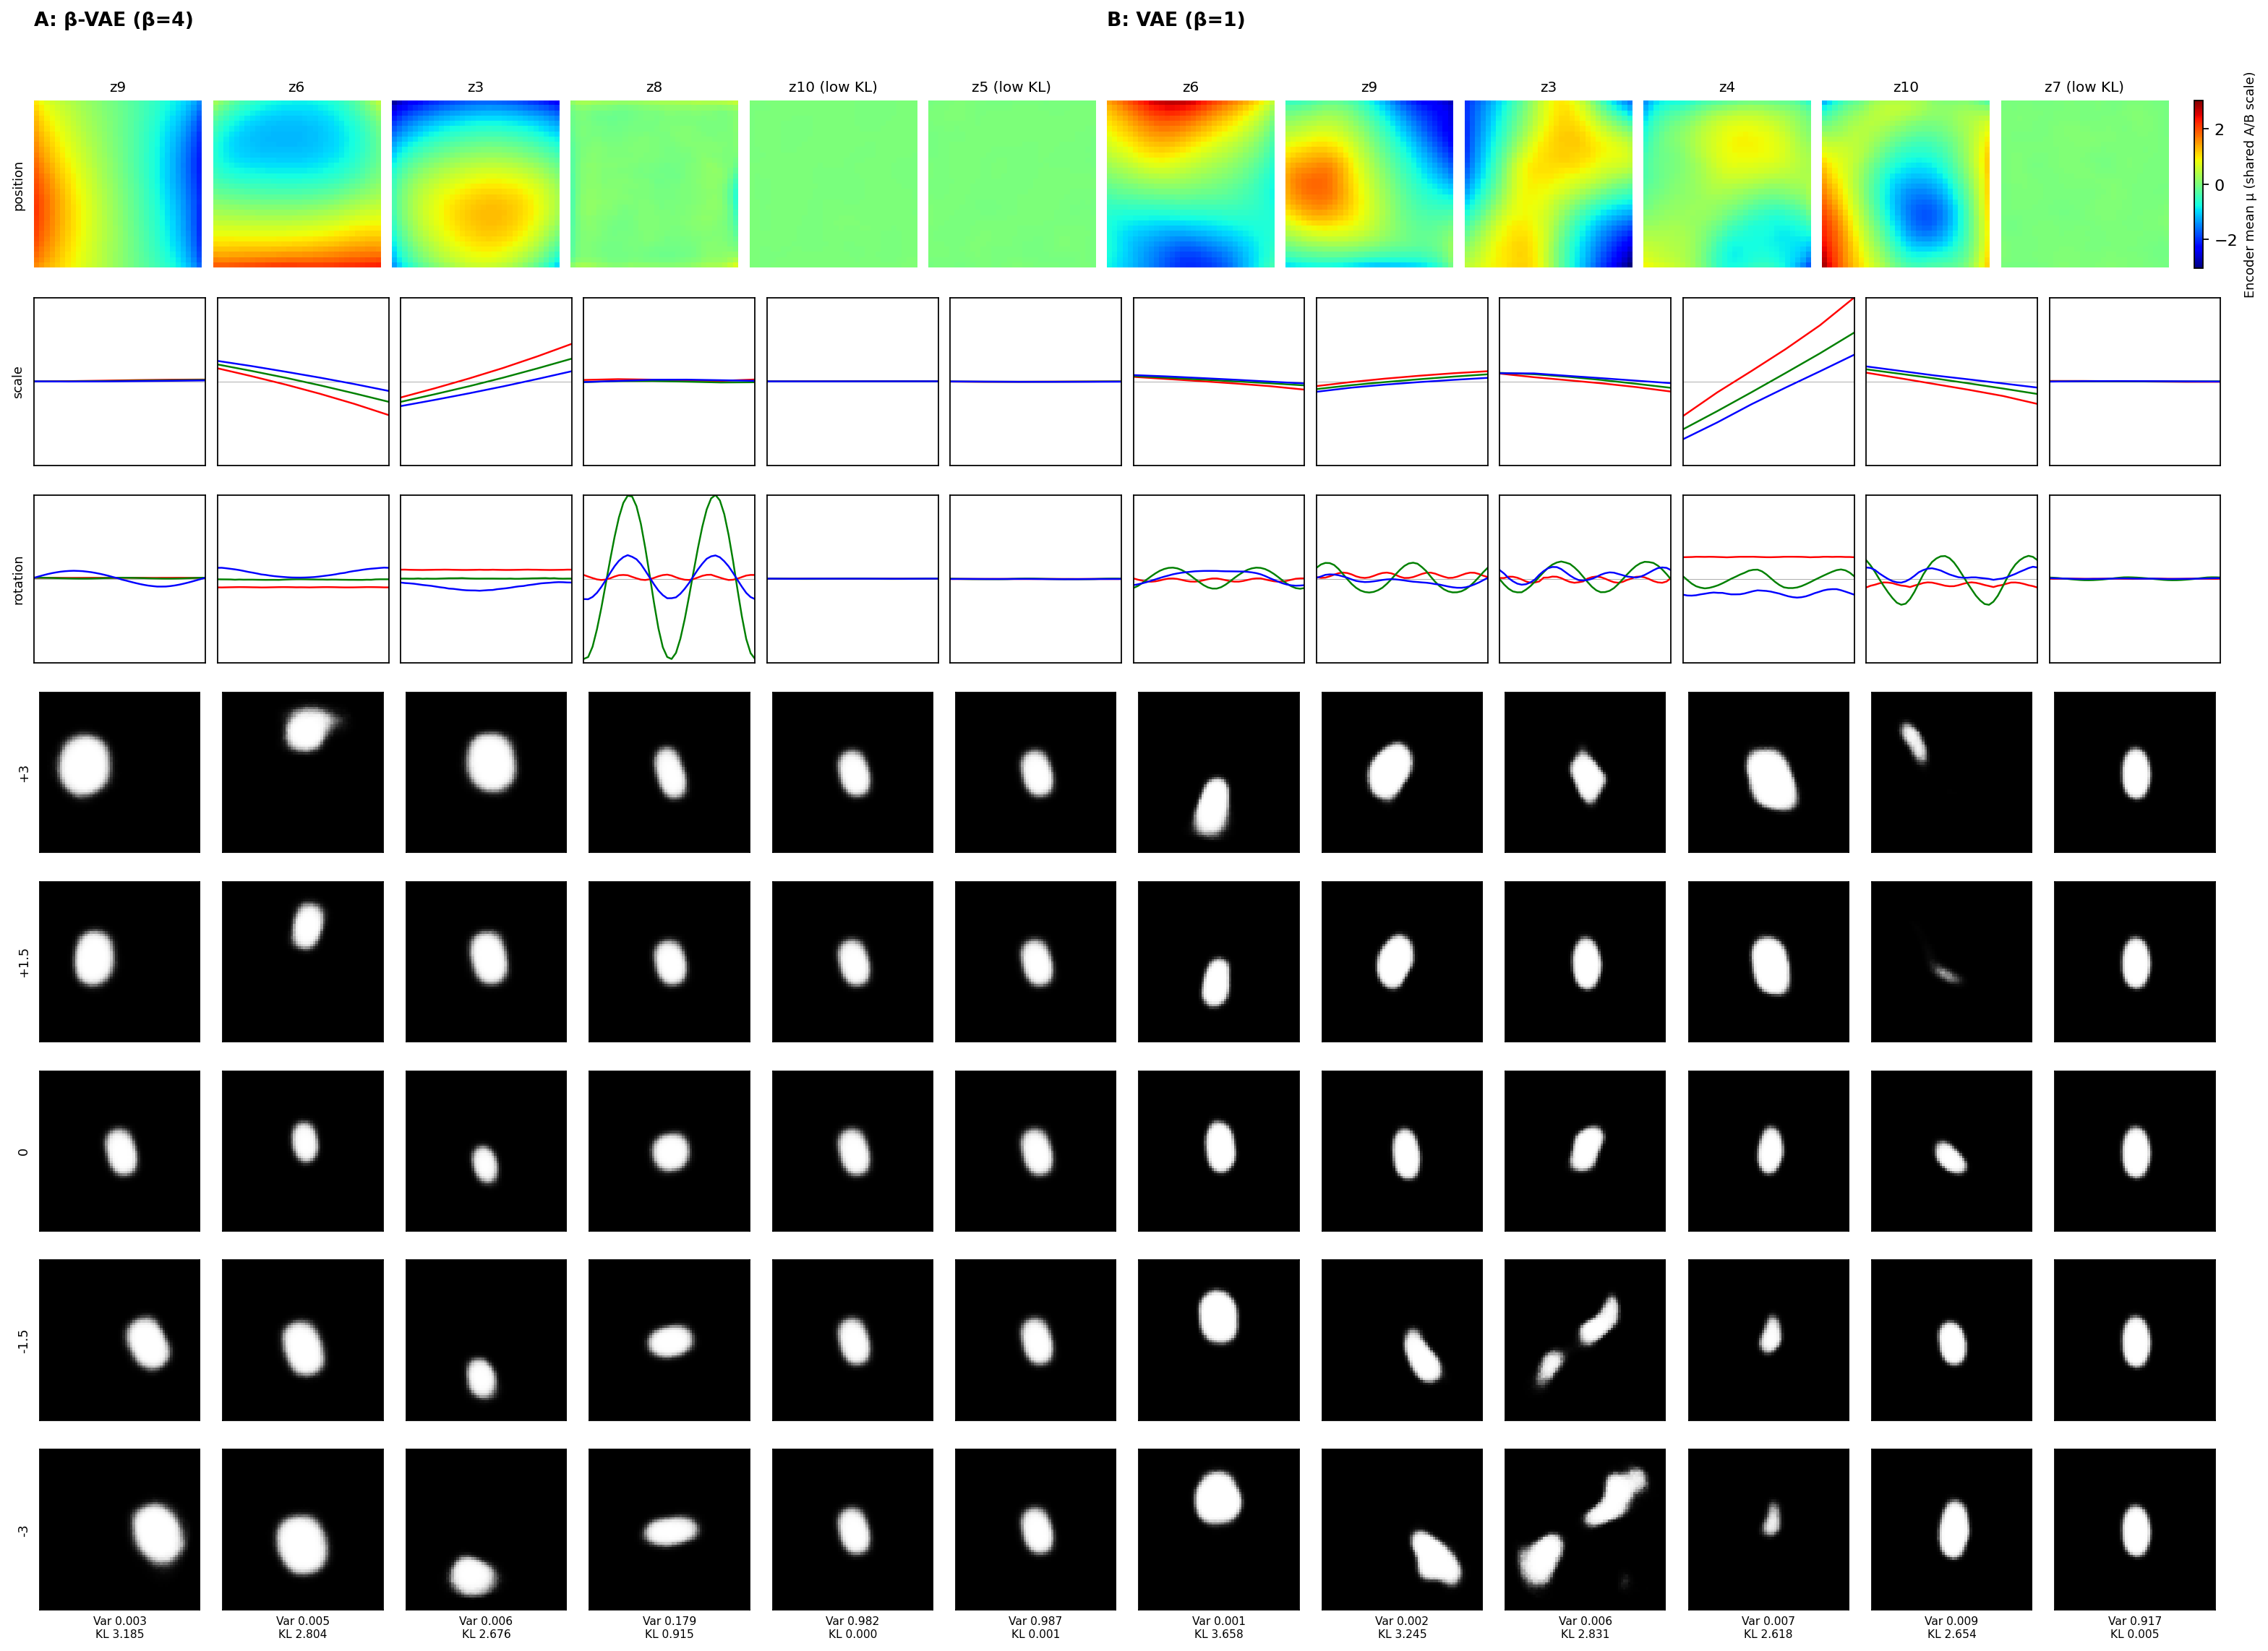


======== FIGURE 7A + 7B | 50,000 STEPS ========


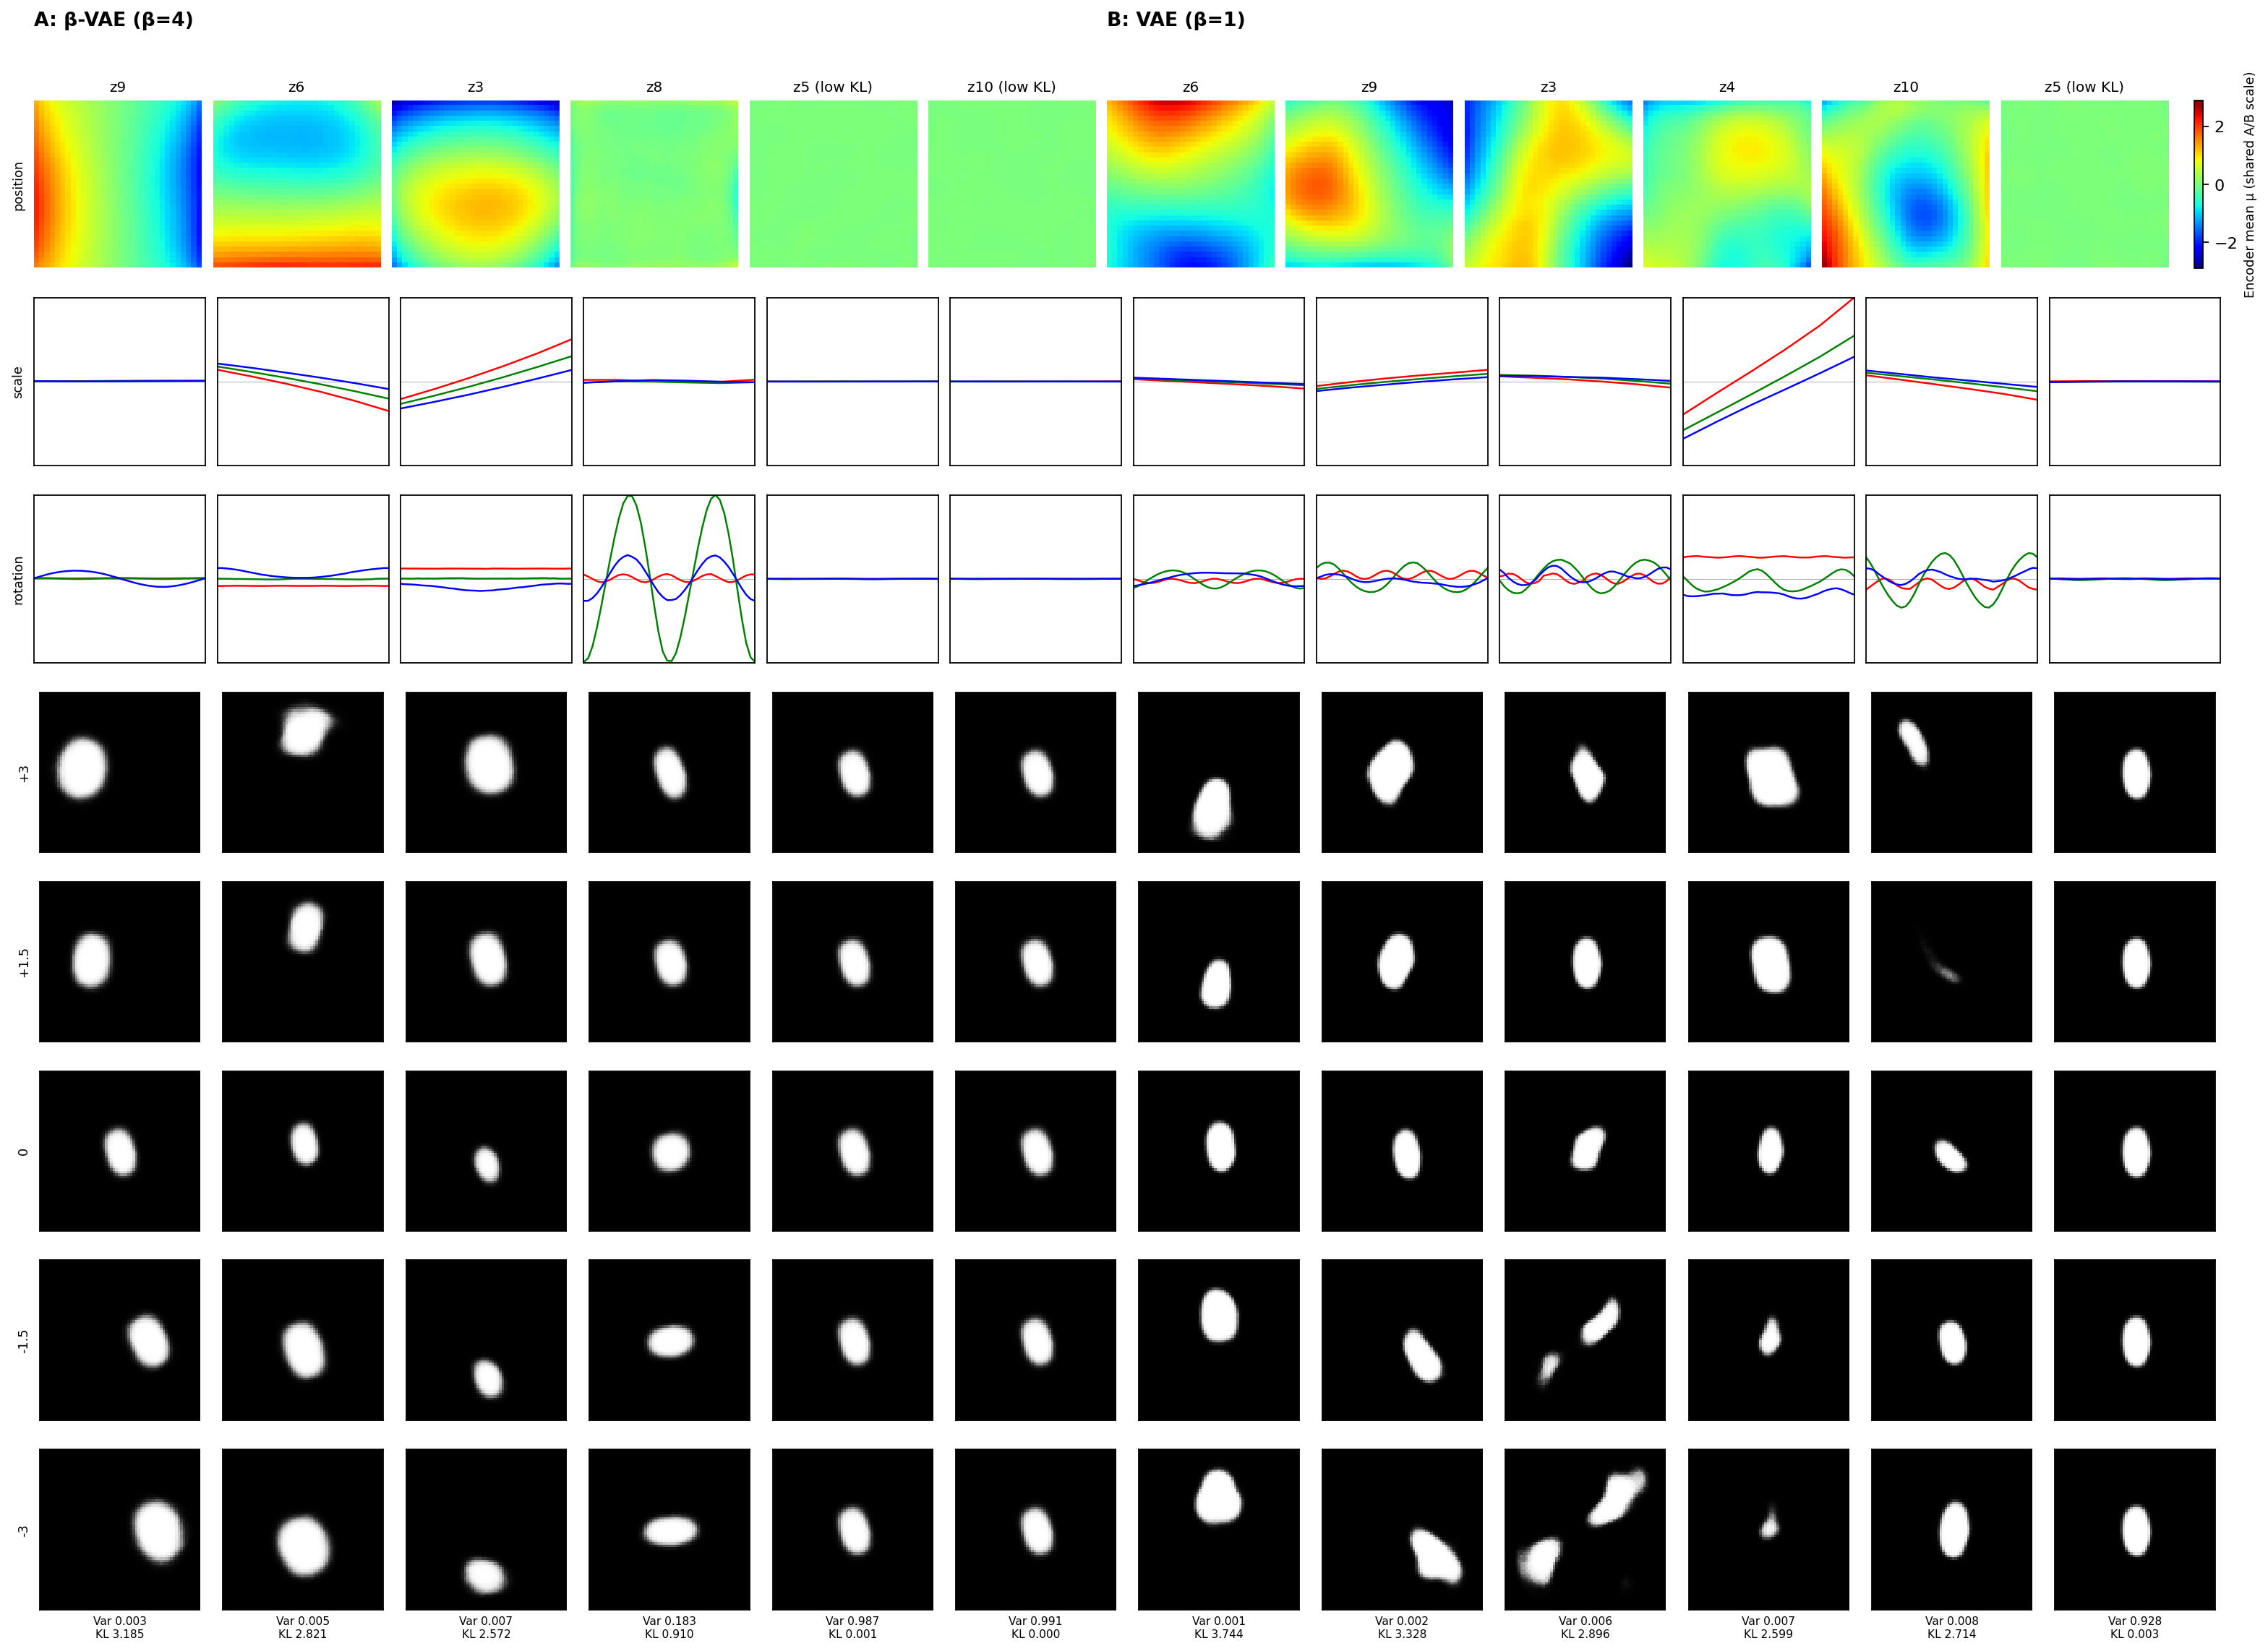


======== FIGURE 7A + 7B | 75,000 STEPS ========


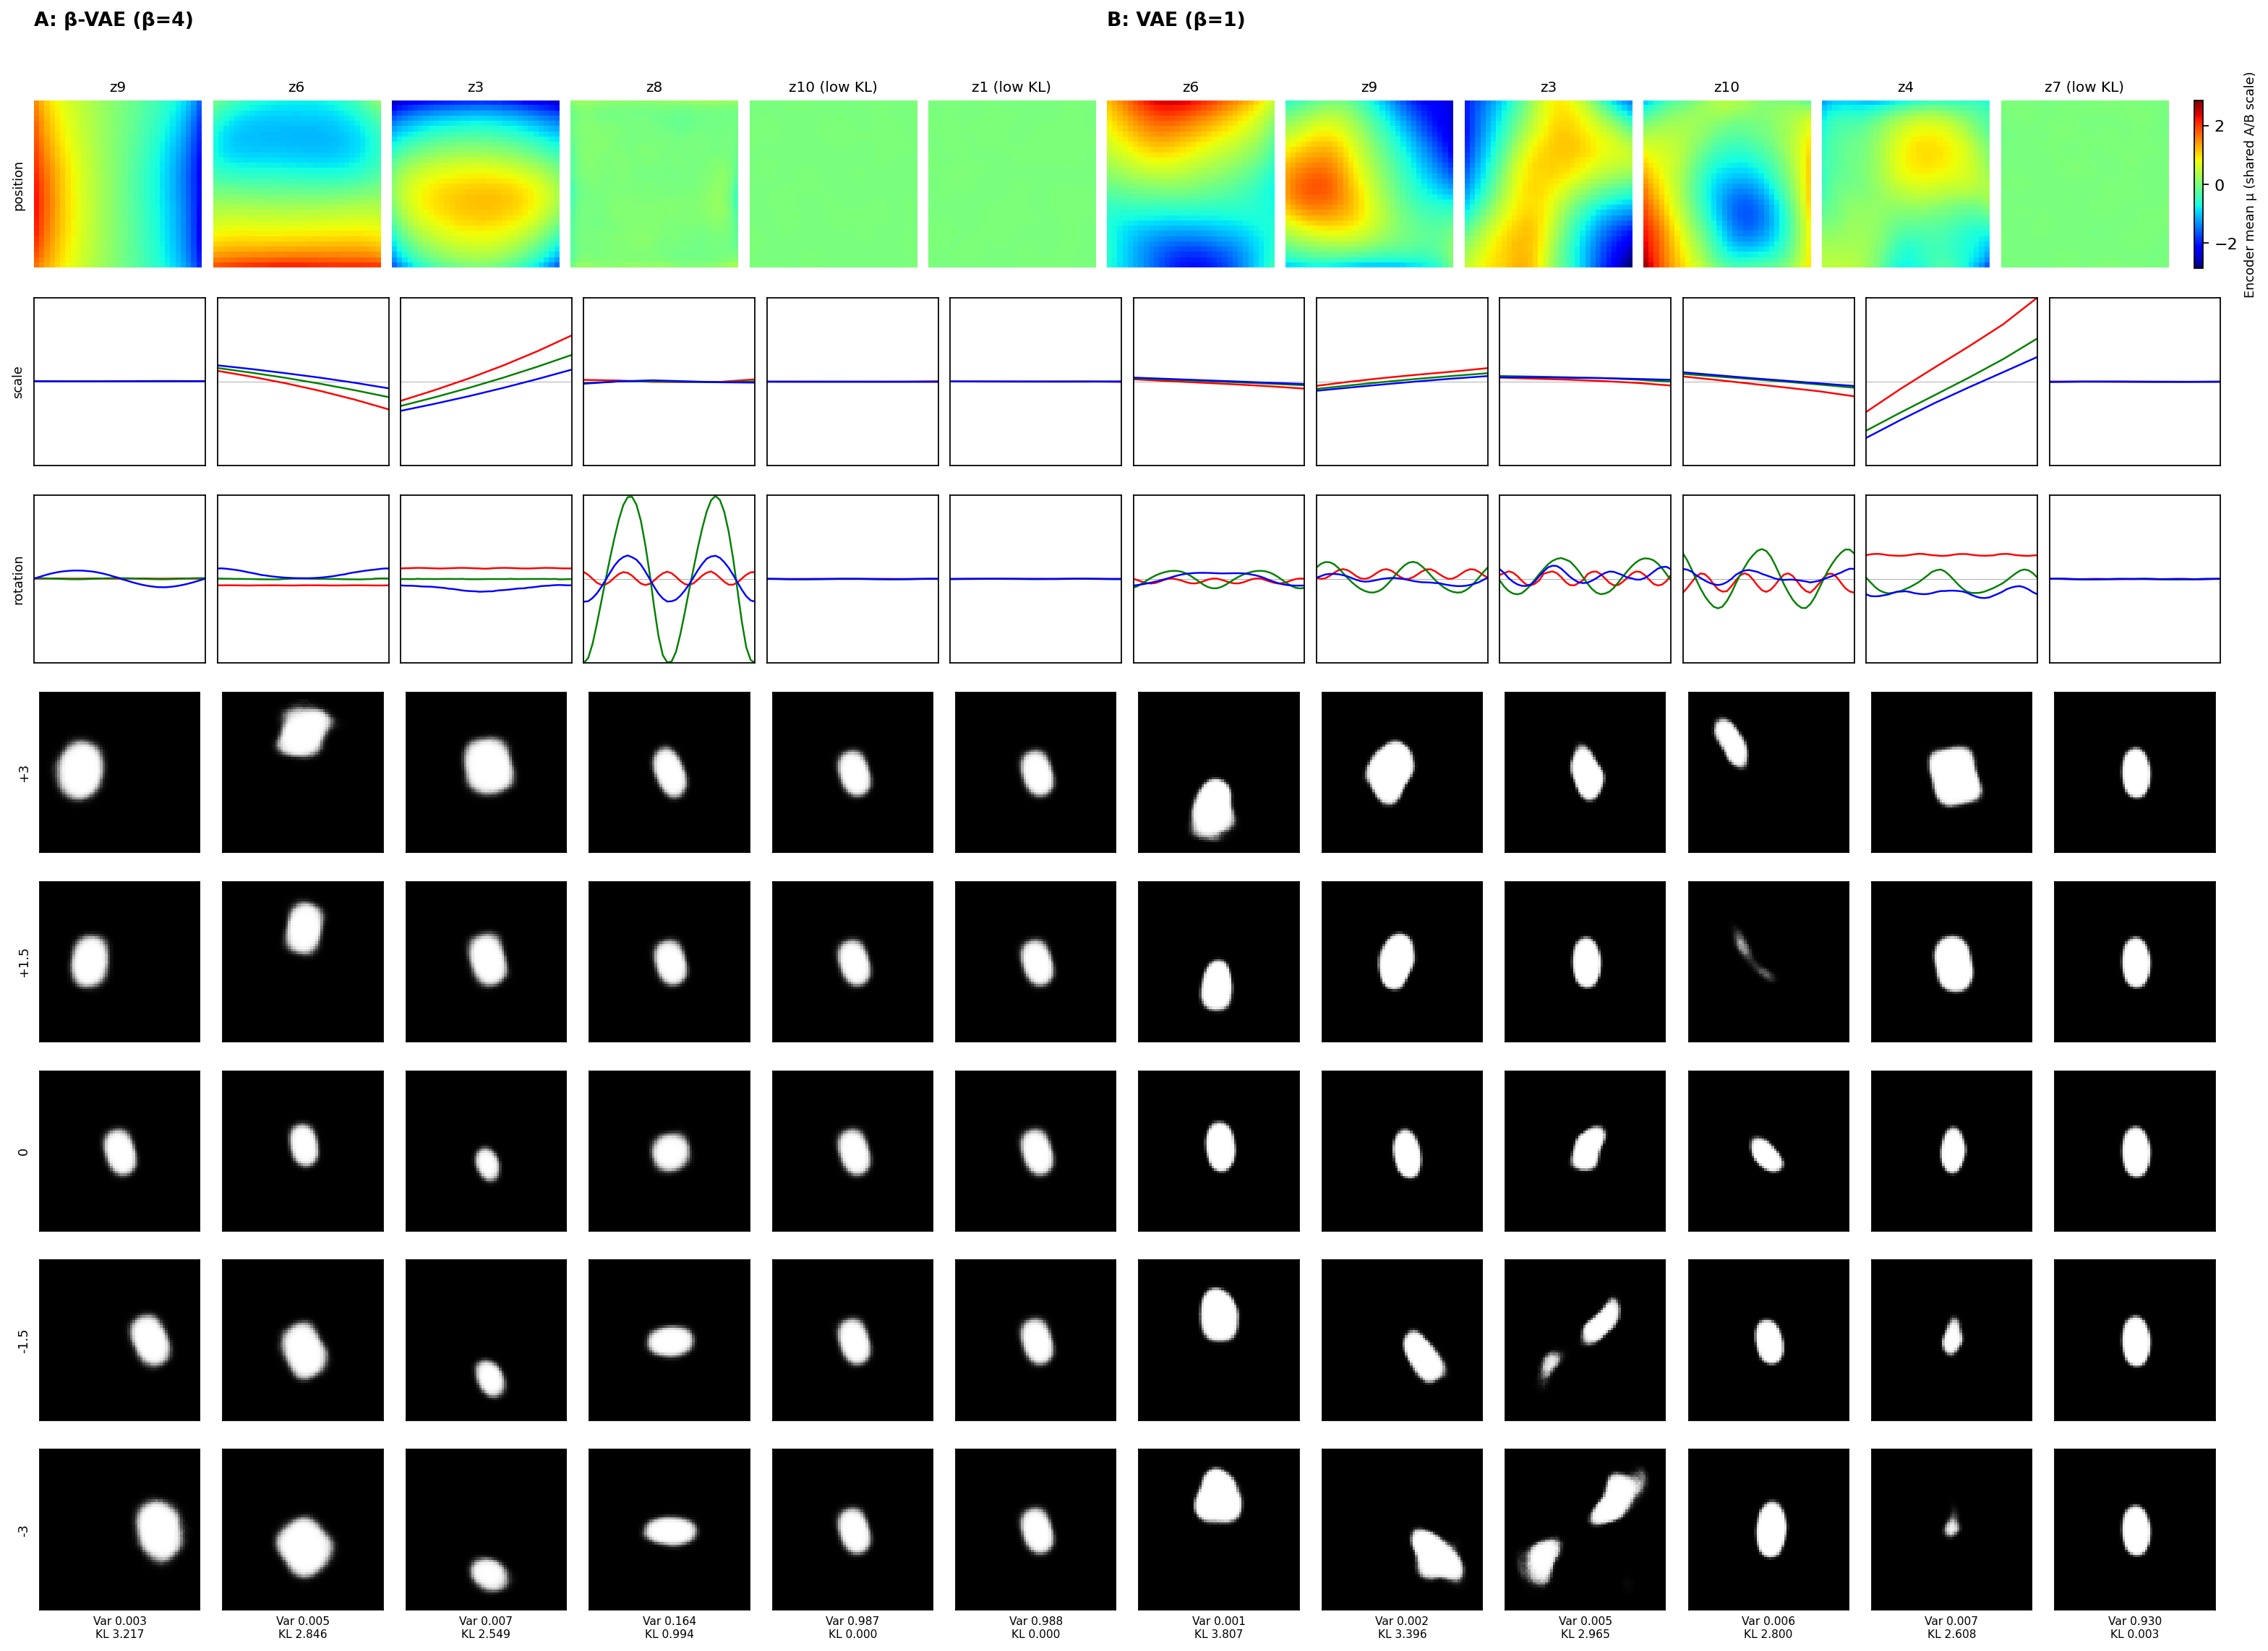


======== FIGURE 7A + 7B | 100,000 STEPS ========


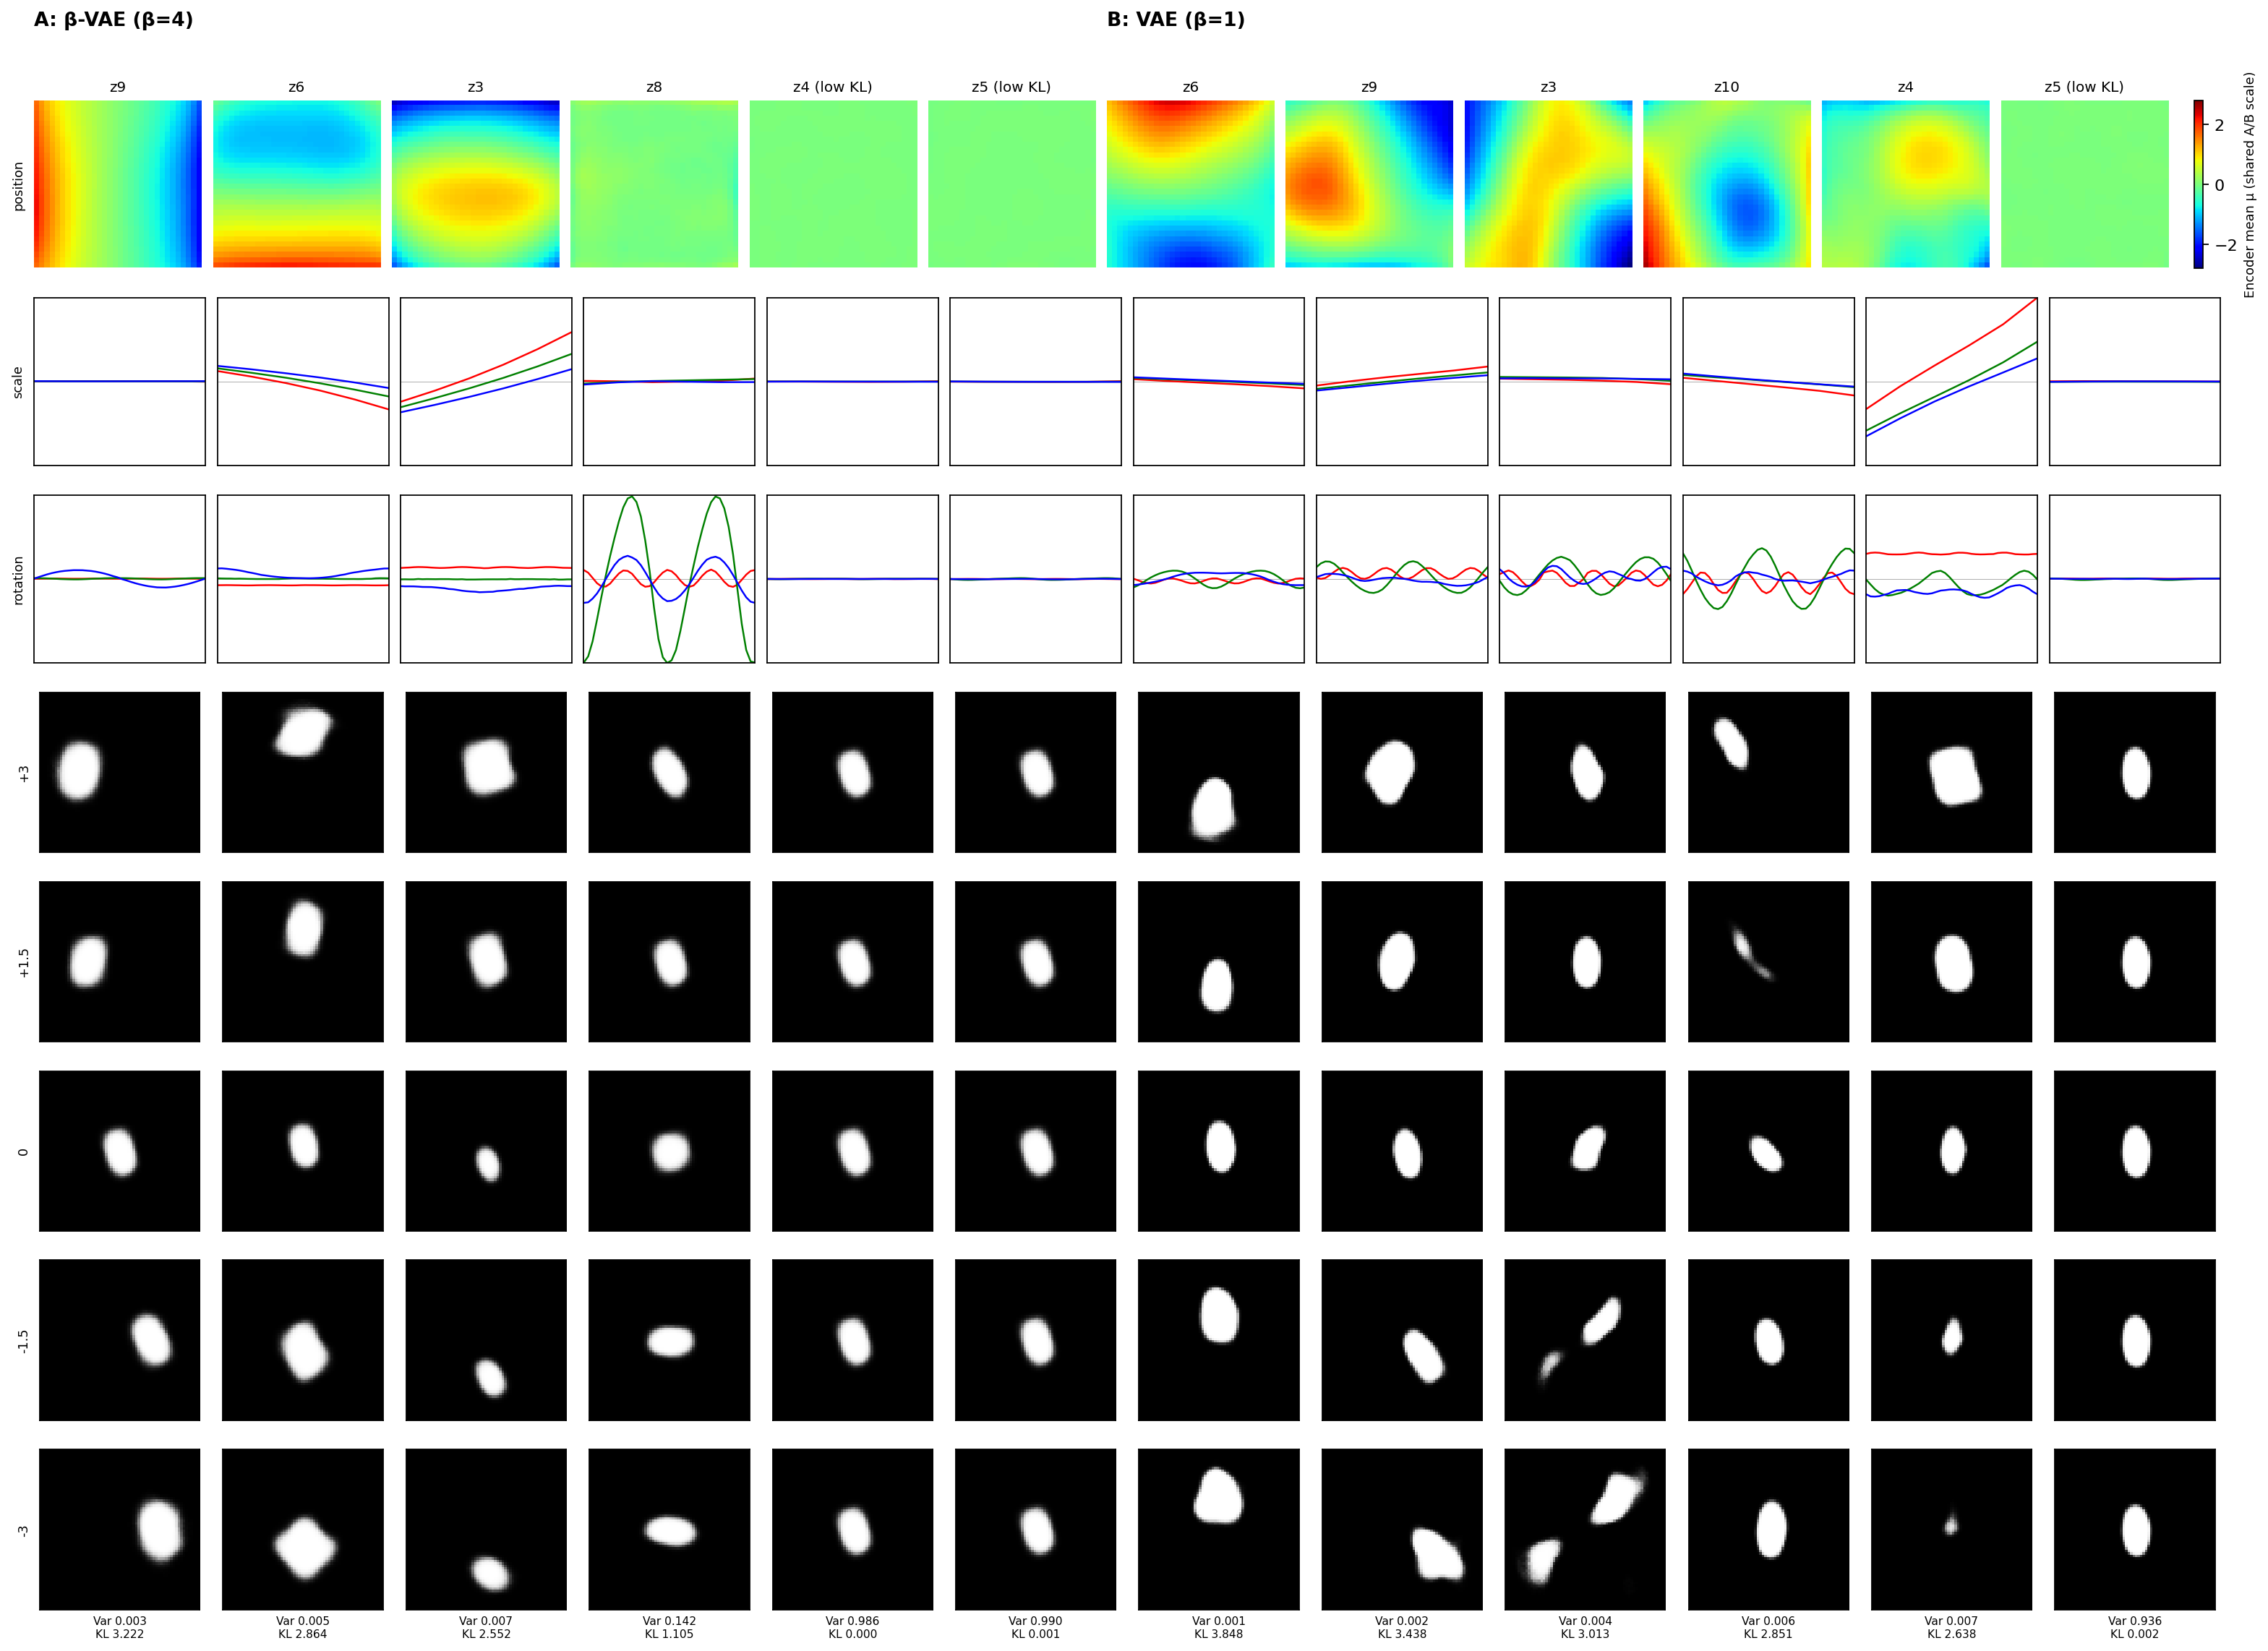

In [ ]:
from IPython.display import display, Image
for step in (30000,50000,75000,100000):
    path=FIGURES/f'step{step:06d}'/'figure7_AB.png'
    if not path.is_file(): safe_copy(DRIVE_FIGURES/f'step{step:06d}'/'figure7_AB.png', path)
    print(f'\n======== FIGURE 7A + 7B | {step:,} STEPS ========')
    display(Image(filename=str(path),width=1200))


## 11. Final integrity check and handoff

All milestone files must exist in **Drive**, and the original Phase 3 30k checkpoint hashes must match their archived 30k snapshots. The notebook generates a manifest describing exact SHA-256 hashes, archived file locations and the Git source commit. Upload the **executed notebook** here along with any error messages if a cell fails. We will assess *whether the missing scale factor emerges, whether latent activity changes, and whether the 100k curves/traversals actually look closer to Higgins et al.* before making any Phase 4 code changes.

In [ ]:
manifest={'phase':'4','experiment':'seed42 β=1/4 30k→100k continuation',
          'source_commit':subprocess.check_output(['git','rev-parse','HEAD'],cwd=REPO,text=True).strip(),
          'dataset_path':str(DATA),'batch_size':256,'learning_rate':0.01,
          'steps':[30000,50000,75000,100000], 'checkpoints':{}}
for step in manifest['steps']:
    for beta in (1,4):
        root=DRIVE_MILESTONES/f'step{step:06d}'/f'beta{beta}'
        for fn in ('latest.pt','model.pt'):
            p=root/fn
            assert p.is_file(), f'Missing archived checkpoint: {p}'
            manifest['checkpoints'][f'{step}/beta{beta}/{fn}']={
                'drive_path':str(p),'sha256':file_sha256(p),'bytes':p.stat().st_size}
    for fn in ('figure7_A.png','figure7_B.png','figure7_AB.png','figure7_metrics.json'):
        assert (DRIVE_FIGURES/f'step{step:06d}'/fn).is_file()
for beta in (1,4):
    src=ORIGINAL_30K[beta]
    for fn in ('latest.pt','model.pt'):
        archived=DRIVE_MILESTONES/'step030000'/f'beta{beta}'/fn
        assert file_sha256(src/fn)==file_sha256(archived), 'Original 30k checkpoint was modified!'
manifest_file=DRIVE_PHASE4/'experiment_manifest.json'
manifest_file.write_text(json.dumps(manifest,indent=2))
print('PASS — all milestones and figures archived, original checkpoints unchanged.')
print('Manifest:',manifest_file)
print('Git source:',manifest['source_commit'])
print('Upload this fully executed notebook for the final 30k→100k assessment.')


PASS — all milestones and figures archived, original checkpoints unchanged.
Manifest: /content/drive/MyDrive/ML-Paper-Reproductions/paper3_phase4_seed42/experiment_manifest.json
Git source: 9632c571db714dd2af6c84e8e257c1646c5bcc67
Upload this fully executed notebook for the final 30k→100k assessment.


In [ ]:

import numpy as np
import pandas as pd
import torch
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score
from IPython.display import display
from src.data import DSprites, index_from_factors
from src.evaluate import load_inference

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
ds = DSprites(DATA)

def scale_probe_data(n_contexts=600, seed=2027):
    """Six scale observations per nuisance-factor context; held-out contexts."""
    rng = np.random.default_rng(seed)
    contexts = np.column_stack([
        rng.integers(0, 3, n_contexts),   # shape
        rng.integers(0, 40, n_contexts),  # orientation
        rng.integers(0, 32, n_contexts),  # X
        rng.integers(0, 32, n_contexts),  # Y
    ])
    factors, labels, groups = [], [], []
    for i, (shape, angle, px, py) in enumerate(contexts):
        for scale in range(6):
            factors.append([0, shape, scale, angle, px, py])
            labels.append(scale)
            groups.append(i)
    return (
        index_from_factors(np.asarray(factors, dtype=np.int64)),
        np.asarray(labels),
        np.asarray(groups)
    )

@torch.inference_mode()
def encode_ids(model, ids, batch_size=512):
    pieces = []
    for start in range(0, len(ids), batch_size):
        x = ds.batch(ids[start:start+batch_size]).to(
            DEVICE, dtype=torch.float32
        )
        mu, _ = model.encode(x)
        pieces.append(mu.cpu().numpy())
    return np.concatenate(pieces, axis=0)

IDS, Y_SCALE, GROUPS = scale_probe_data()
train_mask = GROUPS < 450
test_mask = ~train_mask

def probe_checkpoint(checkpoint, beta_label):
    model, meta = load_inference(checkpoint, DEVICE)
    z = encode_ids(model, IDS)

    # Cross-validated across nuisance contexts, NOT images from the same context.
    linear = LogisticRegression(max_iter=1000, C=1.0)
    linear.fit(z[train_mask], Y_SCALE[train_mask])
    linear_acc = accuracy_score(
        Y_SCALE[test_mask], linear.predict(z[test_mask])
    )

    nonlinear = RandomForestClassifier(
        n_estimators=150, min_samples_leaf=3,
        random_state=2027, n_jobs=-1
    )
    nonlinear.fit(z[train_mask], Y_SCALE[train_mask])
    nonlinear_acc = accuracy_score(
        Y_SCALE[test_mask], nonlinear.predict(z[test_mask])
    )

    single = []
    for j in range(z.shape[1]):
        clf = LogisticRegression(max_iter=1000)
        clf.fit(z[train_mask, j:j+1], Y_SCALE[train_mask])
        acc = accuracy_score(
            Y_SCALE[test_mask],
            clf.predict(z[test_mask, j:j+1])
        )
        single.append(acc)

    return {
        "beta": beta_label,
        "step": int(meta["step"]),
        "linear_all": linear_acc,
        "nonlinear_all": nonlinear_acc,
        "best_single": max(single),
        "best_latent": int(np.argmax(single)) + 1,
        "single_latent_accuracies": single
    }

results = []
for beta in (1, 4):
    checkpoint = (
        DRIVE_MILESTONES / "step100000" /
        f"beta{beta}" / "model.pt"
    )
    results.append(probe_checkpoint(checkpoint, beta))

probe_df = pd.DataFrame([
    {
        "β": r["beta"],
        "Steps": r["step"],
        "Linear scale accuracy": r["linear_all"],
        "Nonlinear scale accuracy": r["nonlinear_all"],
        "Best single latent": f'z{r["best_latent"]}',
        "Single-latent accuracy": r["best_single"]
    }
    for r in results
])
display(probe_df)

for r in results:
    print(
        f'\nβ={r["beta"]}, individual latent accuracies:',
        np.round(r["single_latent_accuracies"], 3)
    )
print("\nChance scale-classification accuracy = 1/6 ≈ 0.167")


,β,Steps,Linear scale accuracy,Nonlinear scale accuracy,Best single latent,Single-latent accuracy
0,1,100000,0.366667,0.580000,z4,0.338889
1,4,100000,0.254444,0.573333,z3,0.230000



β=1, individual latent accuracies: [0.206 0.181 0.168 0.339 0.166 0.169 0.18  0.19  0.186 0.184]

β=4, individual latent accuracies: [0.162 0.183 0.23  0.179 0.186 0.19  0.191 0.167 0.168 0.179]

Chance scale-classification accuracy = 1/6 ≈ 0.167


In [ ]:

from pathlib import Path
import shutil, subprocess, sys, json

SWEEP_ROOT = Path("/content/paper3_phase4_beta_sweep")
SWEEP_DRIVE = DRIVE_BASE / "paper3_phase4_beta_sweep"

SWEEP_LIVE = SWEEP_ROOT / "live"
SWEEP_BACKUP = SWEEP_DRIVE / "live"
SWEEP_MILESTONES = SWEEP_DRIVE / "milestones"
SWEEP_FIGURES = SWEEP_DRIVE / "figures"

for p in (SWEEP_ROOT, SWEEP_LIVE, SWEEP_BACKUP,
          SWEEP_MILESTONES, SWEEP_FIGURES):
    p.mkdir(parents=True, exist_ok=True)

# Preserve the original code. Only expand which beta values it accepts.
SOURCE_COPY = SWEEP_ROOT / "src"
if SOURCE_COPY.exists():
    shutil.rmtree(SOURCE_COPY)
shutil.copytree(
    PROJECT / "src",
    SOURCE_COPY,
    ignore=shutil.ignore_patterns("__pycache__", "*.pyc")
)

train_file = SOURCE_COPY / "train.py"
original = train_file.read_text()

old_guard = "if args.beta not in (1, 4):"
new_guard = "if args.beta not in (1, 2, 3, 4):"

old_choices = "choices=[1.0, 4.0]"
new_choices = "choices=[1.0, 2.0, 3.0, 4.0]"

assert original.count(old_guard) == 1
assert original.count(old_choices) == 1

modified = original.replace(old_guard, new_guard)
modified = modified.replace(old_choices, new_choices)
train_file.write_text(modified)

# Record exactly what changed for the Phase 4 report.
patch_record = {
    "purpose": "Intermediate-beta bottleneck ablation",
    "source_repo": str(REPO),
    "source_commit": subprocess.check_output(
        ["git", "rev-parse", "HEAD"],
        cwd=REPO, text=True
    ).strip(),
    "modified_file": "src/train.py (Phase 4 copy only)",
    "changes": [
        f"{old_guard} -> {new_guard}",
        f"{old_choices} -> {new_choices}"
    ],
    "beta_values": [2, 3],
    "seed": 42,
    "batch_size": 256,
    "learning_rate": 0.01,
    "max_steps": 100000
}

record_path = SWEEP_DRIVE / "experiment_config.json"
record_path.write_text(json.dumps(patch_record, indent=2))

print("Prepared Phase 4 training workspace:", SWEEP_ROOT)
print("Original source unchanged:", PROJECT / "src")
print(json.dumps(patch_record, indent=2))


Prepared Phase 4 training workspace: /content/paper3_phase4_beta_sweep
Original source unchanged: /content/advanced-ml-paper-reproductions/paper3-beta-vae/src
{
  "purpose": "Intermediate-beta bottleneck ablation",
  "source_repo": "/content/advanced-ml-paper-reproductions",
  "source_commit": "9632c571db714dd2af6c84e8e257c1646c5bcc67",
  "modified_file": "src/train.py (Phase 4 copy only)",
  "changes": [
    "if args.beta not in (1, 4): -> if args.beta not in (1, 2, 3, 4):",
    "choices=[1.0, 4.0] -> choices=[1.0, 2.0, 3.0, 4.0]"
  ],
  "beta_values": [
    2,
    3
  ],
  "seed": 42,
  "batch_size": 256,
  "learning_rate": 0.01,
  "max_steps": 100000
}


In [ ]:

import os
import subprocess
import shutil
import torch

TARGETS = (30000, 50000, 100000)

def train_intermediate_beta(beta, target):
    assert beta in (2, 3)
    assert target in TARGETS

    name = f"beta{beta}"
    local = SWEEP_LIVE / name
    remote = SWEEP_BACKUP / name
    local.mkdir(parents=True, exist_ok=True)
    remote.mkdir(parents=True, exist_ok=True)

    # Resume from Drive after a restarted Colab runtime.
    if not (local / "latest.pt").is_file():
        if (remote / "latest.pt").is_file():
            for filename in ("latest.pt", "model.pt"):
                src = remote / filename
                if src.is_file():
                    safe_copy(src, local / filename)

    cmd = [
        sys.executable, "-u", "-m", "src.train",
        "--beta", str(beta),
        "--seed", "42",
        "--max-steps", str(target),
        "--batch-size", "256",
        "--learning-rate", "0.01",
        "--data", str(DATA),
        "--output-root", str(SWEEP_LIVE),
        "--backup-root", str(SWEEP_BACKUP),
        "--ckpt-every", "2000",
        "--log-every", "500",
        "--device", "cuda"
    ]

    print(
        f"\n===== β={beta}, target={target:,} steps =====",
        flush=True
    )

    # Do NOT capture stdout: show real training logs as they happen.
    subprocess.run(cmd, cwd=SWEEP_ROOT, check=True)

    checkpoint = torch.load(
        local / "latest.pt",
        map_location="cpu",
        weights_only=False
    )
    assert int(checkpoint["step"]) == target
    assert float(checkpoint["beta"]) == beta
    assert int(checkpoint["seed"]) == 42
    assert int(checkpoint["batch_size"]) == 256
    assert abs(float(checkpoint["learning_rate"]) - .01) < 1e-12

    milestone = SWEEP_MILESTONES / f"step{target:06d}" / name
    milestone.mkdir(parents=True, exist_ok=True)

    for filename in ("latest.pt", "model.pt", "history.json"):
        src = local / filename
        dst = milestone / filename
        if src.is_file():
            if dst.exists():
                assert file_sha256(src) == file_sha256(dst), (
                    f"Existing milestone differs: {dst}"
                )
            else:
                safe_copy(src, dst)

    print(f"Verified and archived β={beta}, step={target:,}")
    return milestone


# A completed milestone is not retrained.
# Resuming an interrupted run uses the saved optimizer/RNG state.
for target in TARGETS:
    for beta in (2, 3):
        train_intermediate_beta(beta, target)

print("\nβ=2 and β=3 training completed through 100,000 steps.")



===== β=2, target=30,000 steps =====
Verified and archived β=2, step=30,000

===== β=3, target=30,000 steps =====
Verified and archived β=3, step=30,000

===== β=2, target=50,000 steps =====
Verified and archived β=2, step=50,000

===== β=3, target=50,000 steps =====
Verified and archived β=3, step=50,000

===== β=2, target=100,000 steps =====
Verified and archived β=2, step=100,000

===== β=3, target=100,000 steps =====
Verified and archived β=3, step=100,000

β=2 and β=3 training completed through 100,000 steps.


Evaluating β=2 at 30,000 steps
Evaluating β=3 at 30,000 steps
Evaluating β=2 at 50,000 steps
Evaluating β=3 at 50,000 steps
Evaluating β=2 at 100,000 steps
Evaluating β=3 at 100,000 steps


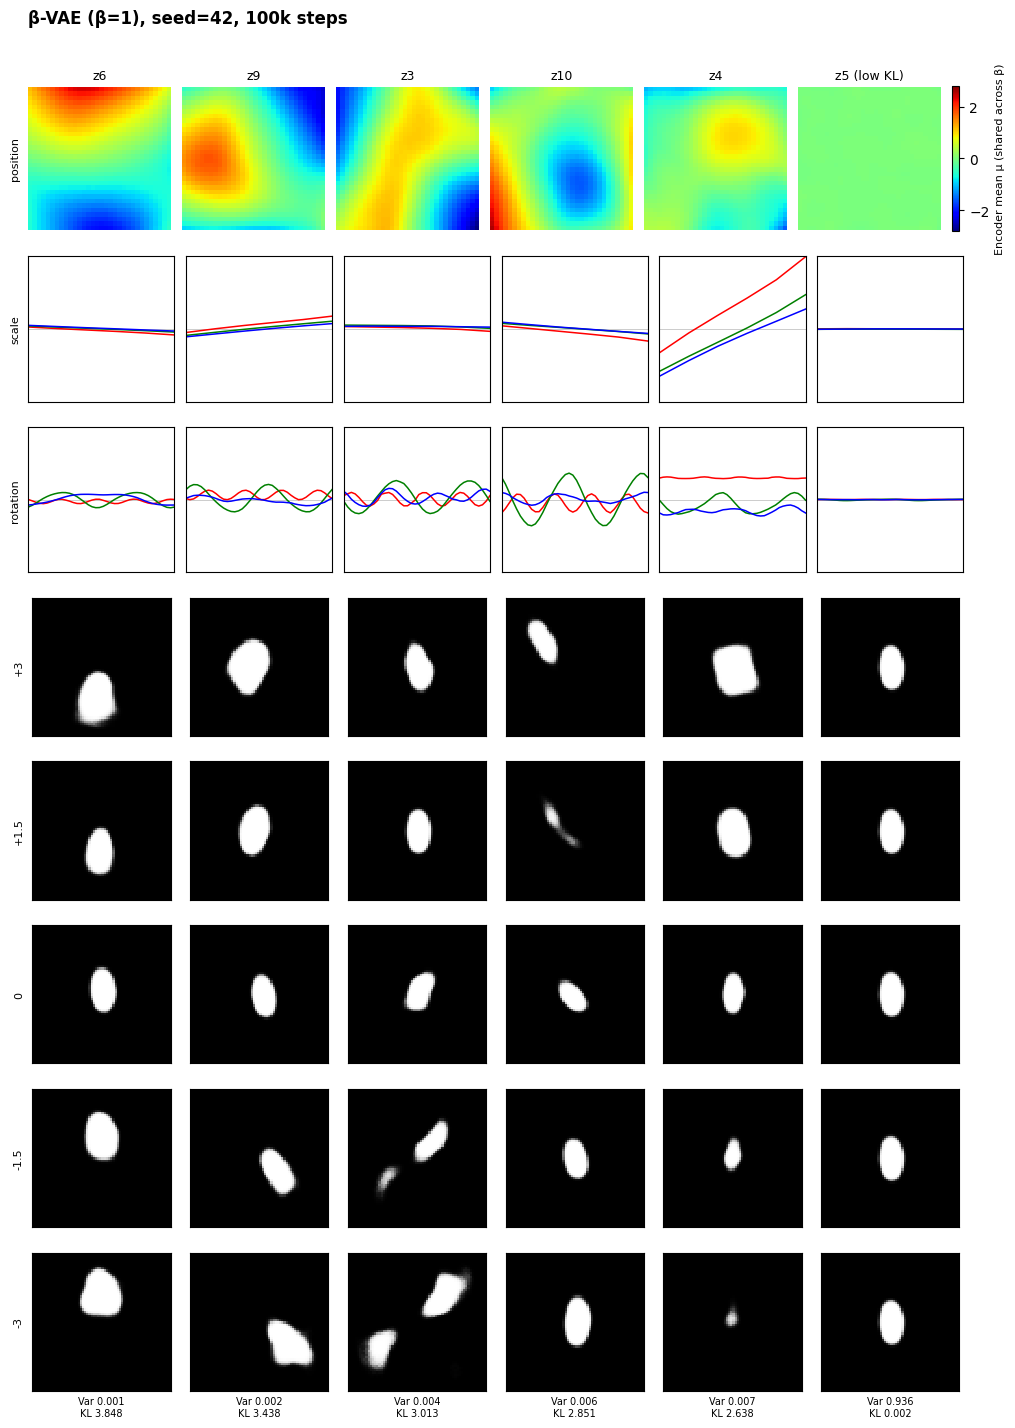

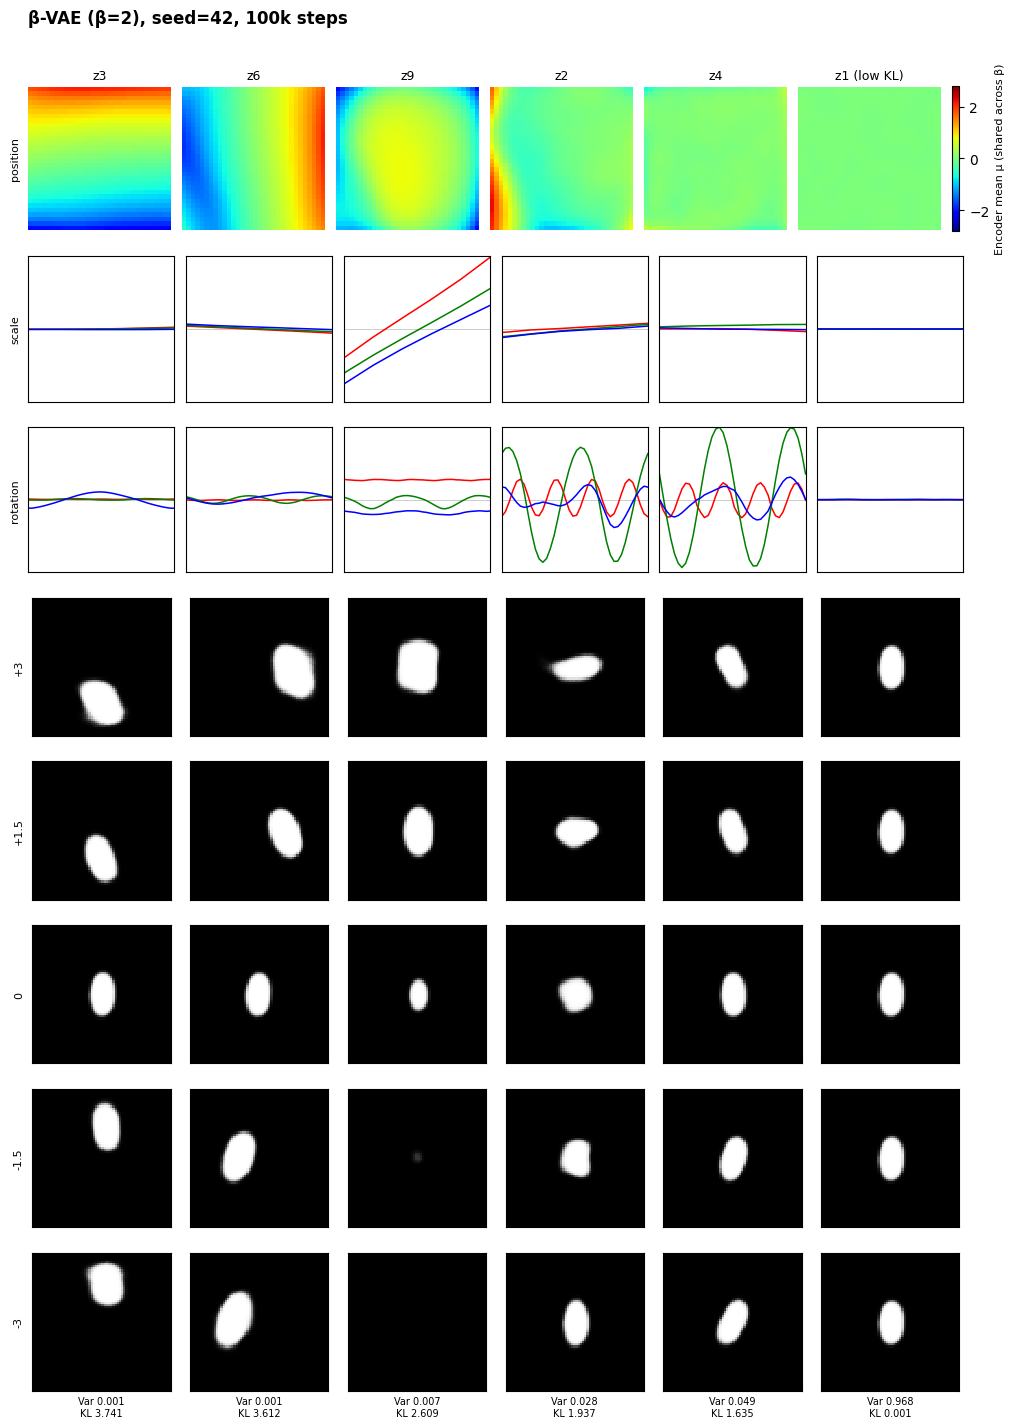

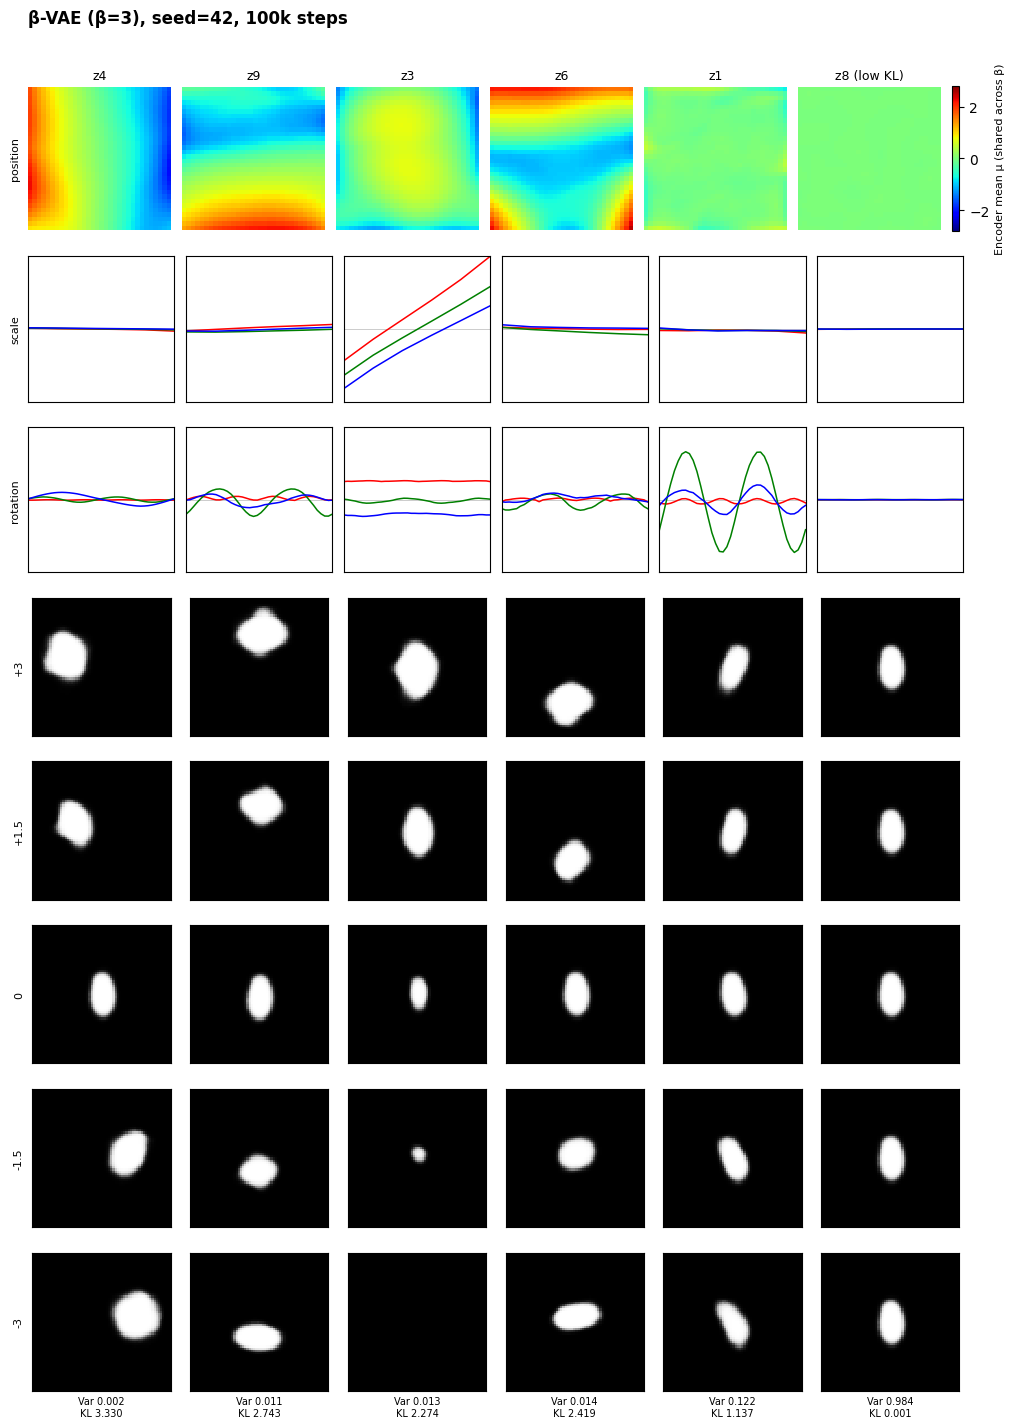

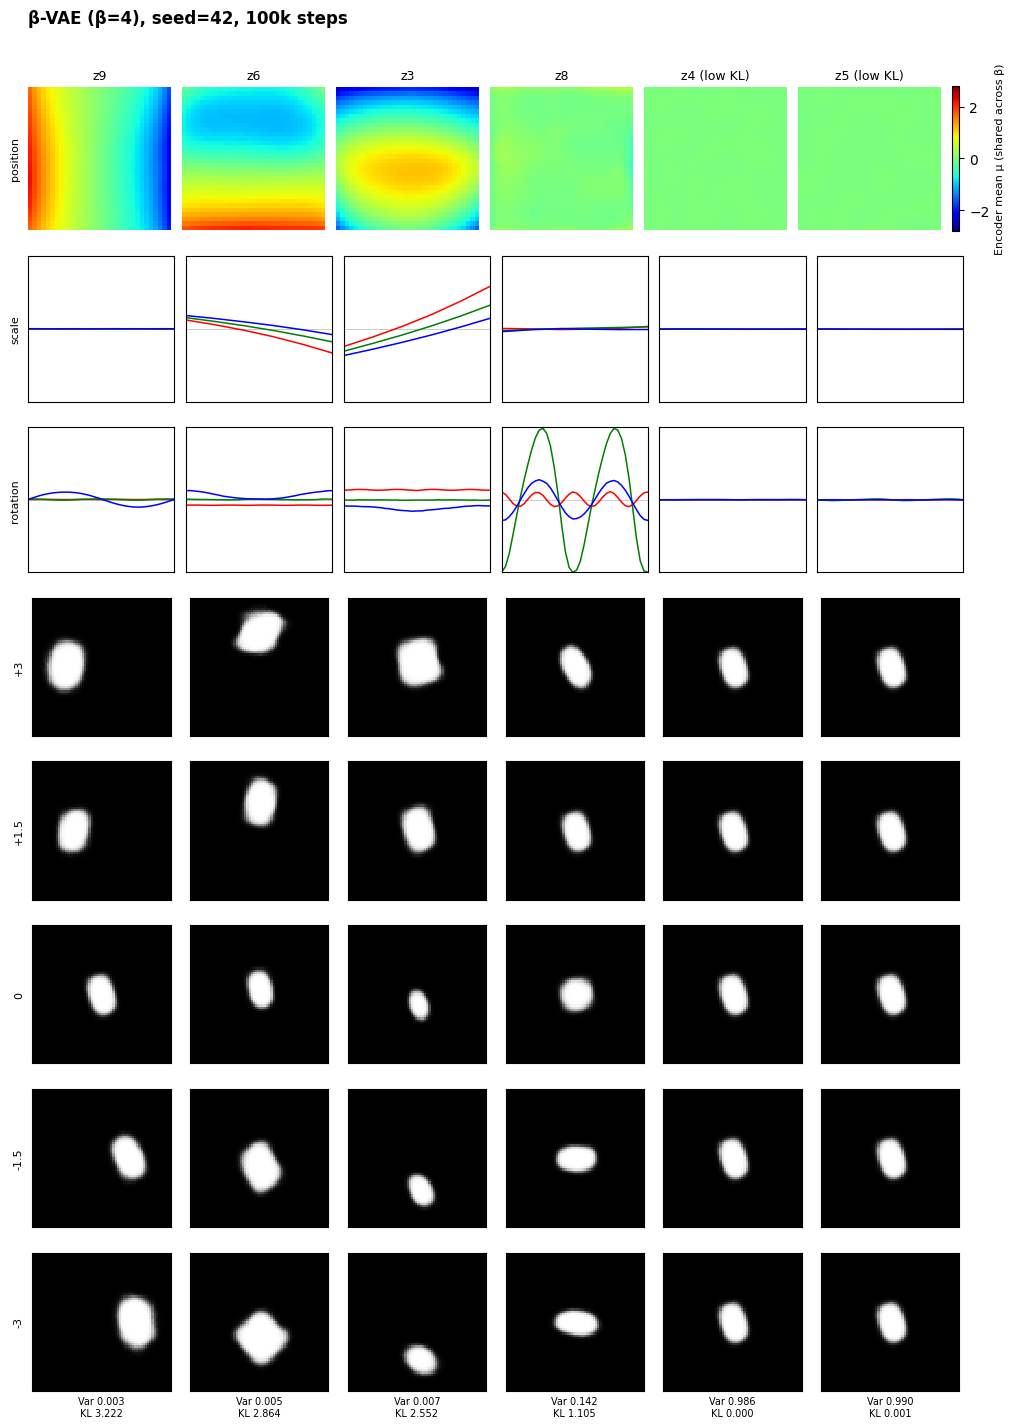

,β,Steps,BCE/image,KL/image,Active latents,Best scale latent,Scale fraction
0,1,100000,43.395850,18.313465,6,z4,0.738098
1,2,100000,53.315398,13.561474,5,z9,0.591701
2,3,100000,65.426547,11.901971,5,z3,0.698454
3,4,100000,80.767773,9.742158,4,z3,0.175774


All figures and metrics saved to: /content/drive/MyDrive/ML-Paper-Reproductions/paper3_phase4_beta_sweep/figures/step100000


In [ ]:

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import json
from IPython.display import display
from src.visualize import (
    data_for_panel, shared_limits, draw_panel, report
)

ds = DSprites(DATA)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
eval_batch = 2048 if DEVICE.type == "cuda" else 512

def plot_beta_panel(panel, beta, limits, destination):
    fig, axes = plt.subplots(
        8, 6, figsize=(11, 15),
        gridspec_kw={
            "height_ratios": [1.05, 1.05, 1.05, 1, 1, 1, 1, 1]
        }
    )
    image = draw_panel(panel, axes, "A", limits)

    # Replace the draw helper's fixed "A: beta=4" heading.
    for txt in axes[0, 0].texts:
        txt.set_text(f"β-VAE (β={beta}), seed=42, 100k steps")

    fig.subplots_adjust(
        wspace=.08, hspace=.18,
        left=.08, right=.93, top=.95, bottom=.08
    )
    cb = fig.colorbar(
        image, ax=list(axes[0]), fraction=.012, pad=.012
    )
    cb.set_label("Encoder mean μ (shared across β)", fontsize=8)

    fig.savefig(destination, dpi=140, bbox_inches="tight")
    display(fig)
    plt.close(fig)

# Evaluate intermediate-beta milestones. These are genuine full-dataset
# evaluations; do not substitute any known or expected results.
intermediate_metrics = {}

for step in TARGETS:
    for beta in (2, 3):
        name = f"beta{beta}"
        checkpoint = (
            SWEEP_MILESTONES /
            f"step{step:06d}" /
            name / "model.pt"
        )
        assert checkpoint.is_file(), checkpoint

        print(f"Evaluating β={beta} at {step:,} steps", flush=True)
        panel = data_for_panel(
            checkpoint, ds, DEVICE, eval_batch
        )
        assert float(panel["meta"]["beta"]) == beta
        assert int(panel["meta"]["step"]) == step

        intermediate_metrics[(step, beta)] = panel

        dest = SWEEP_FIGURES / f"step{step:06d}"
        dest.mkdir(parents=True, exist_ok=True)

        # Preserve full numeric diagnostics without hand-entering outcomes.
        limits = shared_limits([panel])
        metrics = report(panel, limits)
        (dest / f"beta{beta}_metrics.json").write_text(
            json.dumps(metrics, indent=2)
        )

# At 100k, also load our already-trained beta 1/4 checkpoints.
final_panels = {
    beta: intermediate_metrics[(100000, beta)]
    for beta in (2, 3)
}

for beta in (1, 4):
    checkpoint = (
        DRIVE_MILESTONES /
        "step100000" /
        f"beta{beta}" /
        "model.pt"
    )
    assert checkpoint.is_file(), checkpoint
    final_panels[beta] = data_for_panel(
        checkpoint, ds, DEVICE, eval_batch
    )

# One common scale across all four models, preventing misleading
# per-model color exaggeration.
common_limits = shared_limits(list(final_panels.values()))
dest = SWEEP_FIGURES / "step100000"
dest.mkdir(parents=True, exist_ok=True)

summary = []
for beta in (1, 2, 3, 4):
    p = final_panels[beta]
    kls = np.asarray(p["factors"]["kl_per_latent"])
    active = kls > 0.1
    fractions = p["factor_diagnostics"][
        "within_4_factor_signal_fractions"
    ]

    scale_values = np.asarray(fractions["scale"])
    best_scale = np.where(
        active,
        scale_values,
        -np.inf
    ).argmax()

    summary.append({
        "β": beta,
        "Steps": int(p["meta"]["step"]),
        "BCE/image": p["diagnostics"]["bce_per_image"],
        "KL/image": p["diagnostics"]["kl_per_image"],
        "Active latents": int(active.sum()),
        "Best scale latent": f"z{best_scale + 1}",
        "Scale fraction": float(scale_values[best_scale])
    })

    plot_beta_panel(
        p, beta, common_limits,
        dest / f"figure_beta{beta}_100k.png"
    )

    (dest / f"beta{beta}_metrics_shared.json").write_text(
        json.dumps(report(p, common_limits), indent=2)
    )

summary_df = pd.DataFrame(summary).sort_values("β")
display(summary_df)

summary_df.to_csv(
    dest / "beta_comparison_100k.csv",
    index=False
)
print("All figures and metrics saved to:", dest)


In [ ]:

all_probe_results = list(results)  # beta 1 and beta 4 from Cell 1

for beta in (2, 3):
    checkpoint = (
        SWEEP_MILESTONES /
        "step100000" /
        f"beta{beta}" /
        "model.pt"
    )
    all_probe_results.append(
        probe_checkpoint(checkpoint, beta)
    )

probe_comparison = pd.DataFrame([
    {
        "β": r["beta"],
        "Steps": r["step"],
        "Linear accuracy": r["linear_all"],
        "Nonlinear accuracy": r["nonlinear_all"],
        "Best single latent": f'z{r["best_latent"]}',
        "Single-latent accuracy": r["best_single"]
    }
    for r in all_probe_results
]).sort_values("β")

display(probe_comparison)

probe_comparison.to_csv(
    SWEEP_FIGURES / "step100000" /
    "scale_decoding_comparison.csv",
    index=False
)

print("Scale classification chance accuracy: 16.67%")
print("Results archived on Drive:", SWEEP_FIGURES)


,β,Steps,Linear accuracy,Nonlinear accuracy,Best single latent,Single-latent accuracy
0,1,100000,0.366667,0.580000,z4,0.338889
2,2,100000,0.418889,0.611111,z9,0.411111
3,3,100000,0.374444,0.586667,z3,0.371111
1,4,100000,0.254444,0.573333,z3,0.230000


Scale classification chance accuracy: 16.67%
Results archived on Drive: /content/drive/MyDrive/ML-Paper-Reproductions/paper3_phase4_beta_sweep/figures
